# Chapter 5: Visualization and exploratory statistics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alilouati/programming-for-data-science/blob/main/05_visualization/lecture.ipynb)

A good chart answers a question at a glance; a bad one misleads. This chapter covers

1. Matplotlib basics: figures and axes
2. Choosing the right chart: line, bar, histogram, scatter, box plot
3. Charts that mislead (and how to fix them)
4. Styling: titles, labels, legends, annotations, saving
5. Several plots in one figure
6. Plotting directly from pandas
7. Statistical plots with seaborn
8. Descriptive statistics and correlation
9. Comparing groups: the t-test
10. A taste of interactive charts with Plotly

In [1]:
# Data files live in the course repository. This works both in Colab and locally.
from pathlib import Path

BASE_URL = "https://raw.githubusercontent.com/alilouati/programming-for-data-science/main/data/"

def data_file(name):
    """Return a local path if the repo is cloned, otherwise the GitHub URL."""
    local = Path("../data") / name
    return local if local.exists() else BASE_URL + name

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

## 1. Matplotlib basics: figures and axes

Always start with `fig, ax = plt.subplots()`. The **figure** is the whole image; an **axes** is one plot inside it. Every customisation is a method of `ax`.

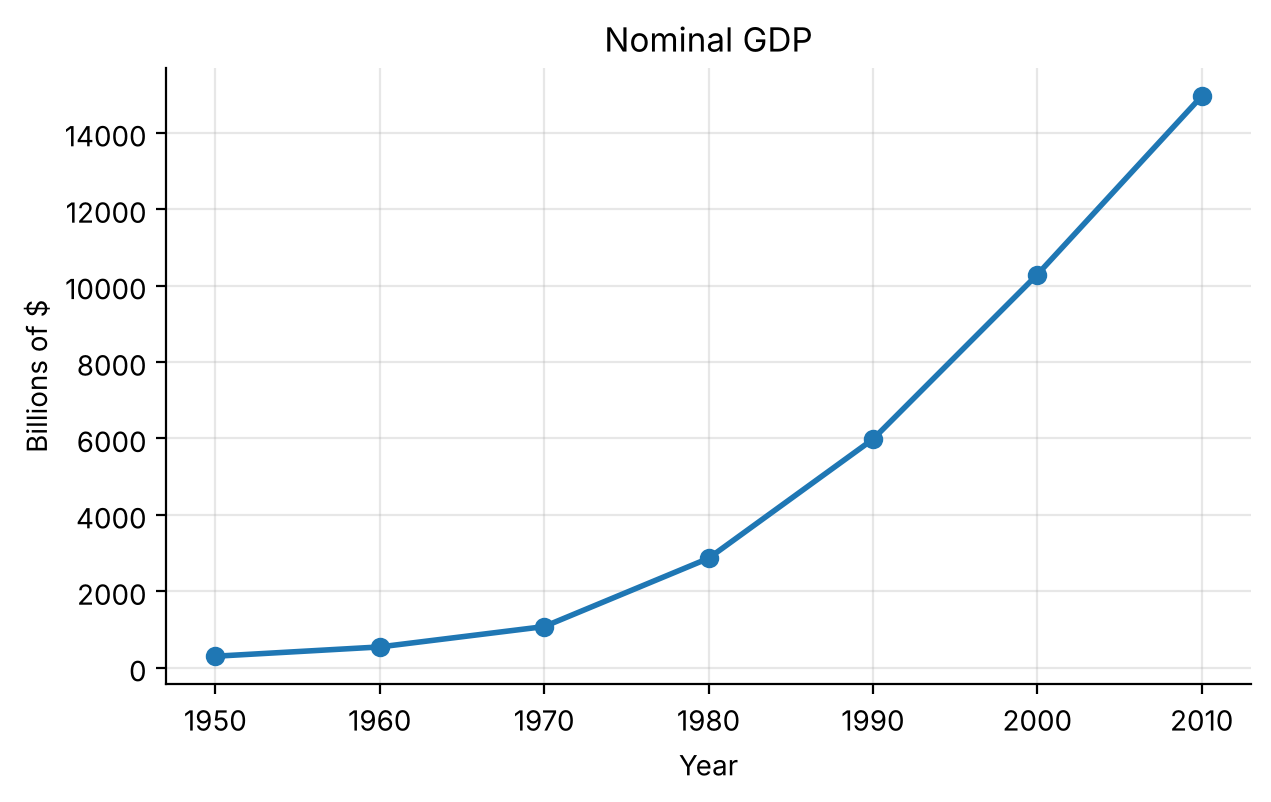

In [3]:
years = list(range(1950, 2011, 10))
gdp = [300.2, 543.3, 1075.9, 2862.5, 5979.6, 10289.7, 14958.3]

fig, ax = plt.subplots()
ax.plot(years, gdp, marker="o", linewidth=2)
ax.set_title("Nominal GDP")
ax.set_xlabel("Year")
ax.set_ylabel("Billions of $")
plt.show()

## 2. Choosing the right chart

| Question | Chart |
|---|---|
| How does a value change over **time**? | line chart |
| How do values compare across **categories**? | bar chart (horizontal if labels are long) |
| How is one variable **distributed**? | histogram, box plot |
| How are two numeric variables **related**? | scatter plot |
| How do distributions compare across groups? | box plot, violin plot |

### Line charts are for trends, not for unordered items

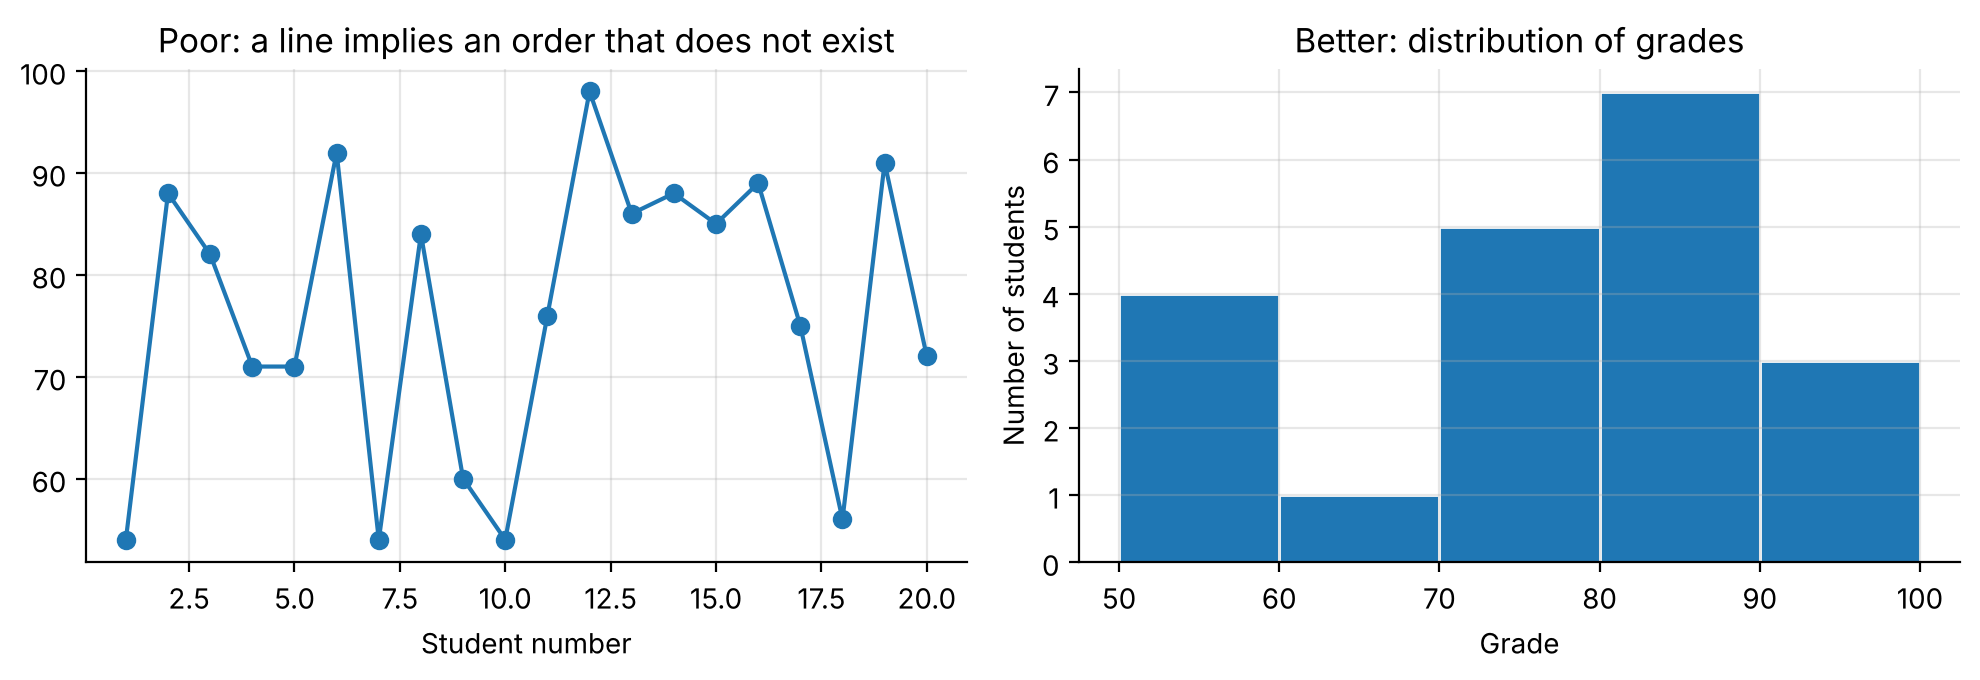

In [4]:
students = rng.integers(50, 100, size=20)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(range(1, 21), students, marker="o")
axes[0].set_title("Poor: a line implies an order that does not exist")
axes[0].set_xlabel("Student number")
axes[1].hist(students, bins=range(50, 101, 10), edgecolor="white")
axes[1].set_title("Better: distribution of grades")
axes[1].set_xlabel("Grade")
axes[1].set_ylabel("Number of students")
plt.tight_layout()
plt.show()

### Bar charts compare categories

Bars must start at zero, because their length encodes the value.

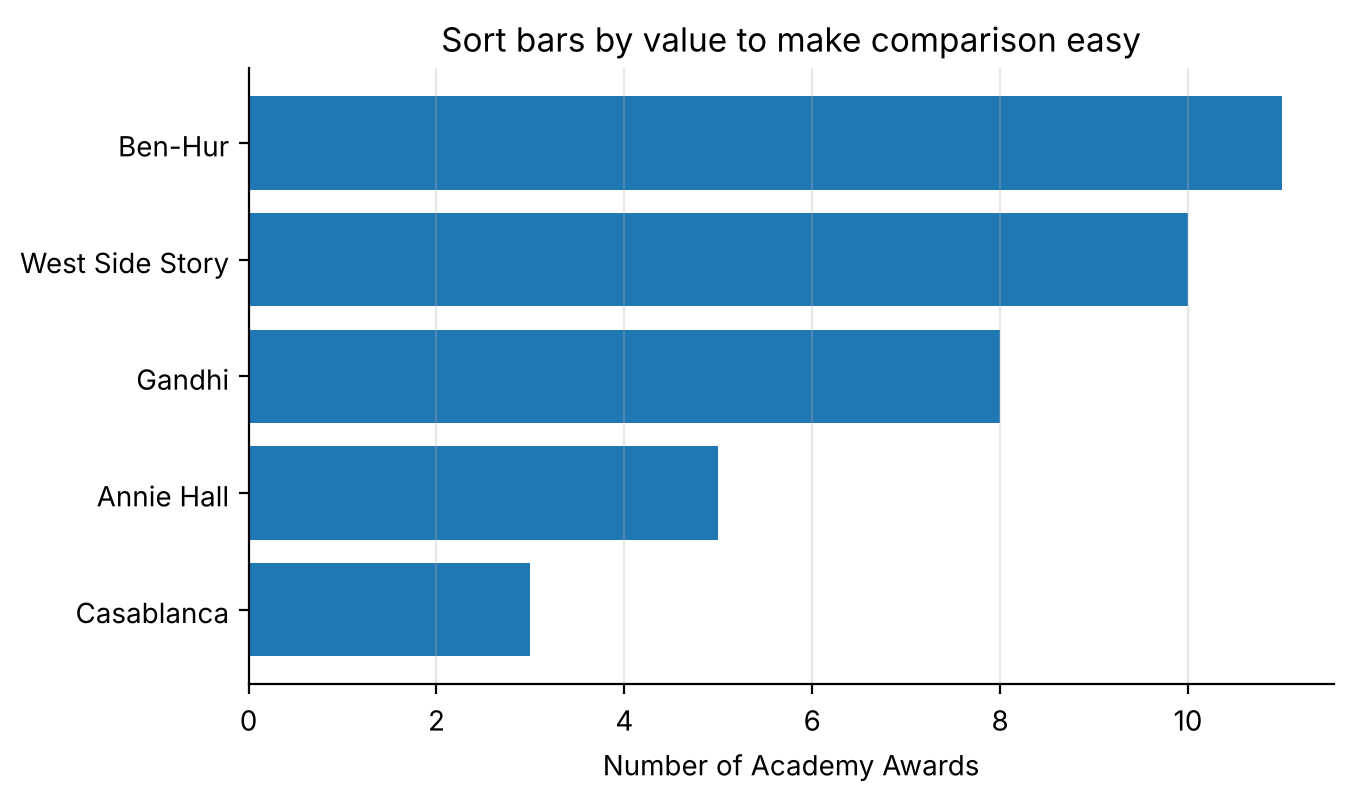

In [5]:
movies = ["Annie Hall", "Ben-Hur", "Casablanca", "Gandhi", "West Side Story"]
oscars = [5, 11, 3, 8, 10]
order = np.argsort(oscars)

fig, ax = plt.subplots()
ax.barh(np.array(movies)[order], np.array(oscars)[order])
ax.set_xlabel("Number of Academy Awards")
ax.set_title("Sort bars by value to make comparison easy")
ax.grid(axis="y", visible=False)
plt.show()

### Histograms show distributions

The number of bins changes the story; try a few.

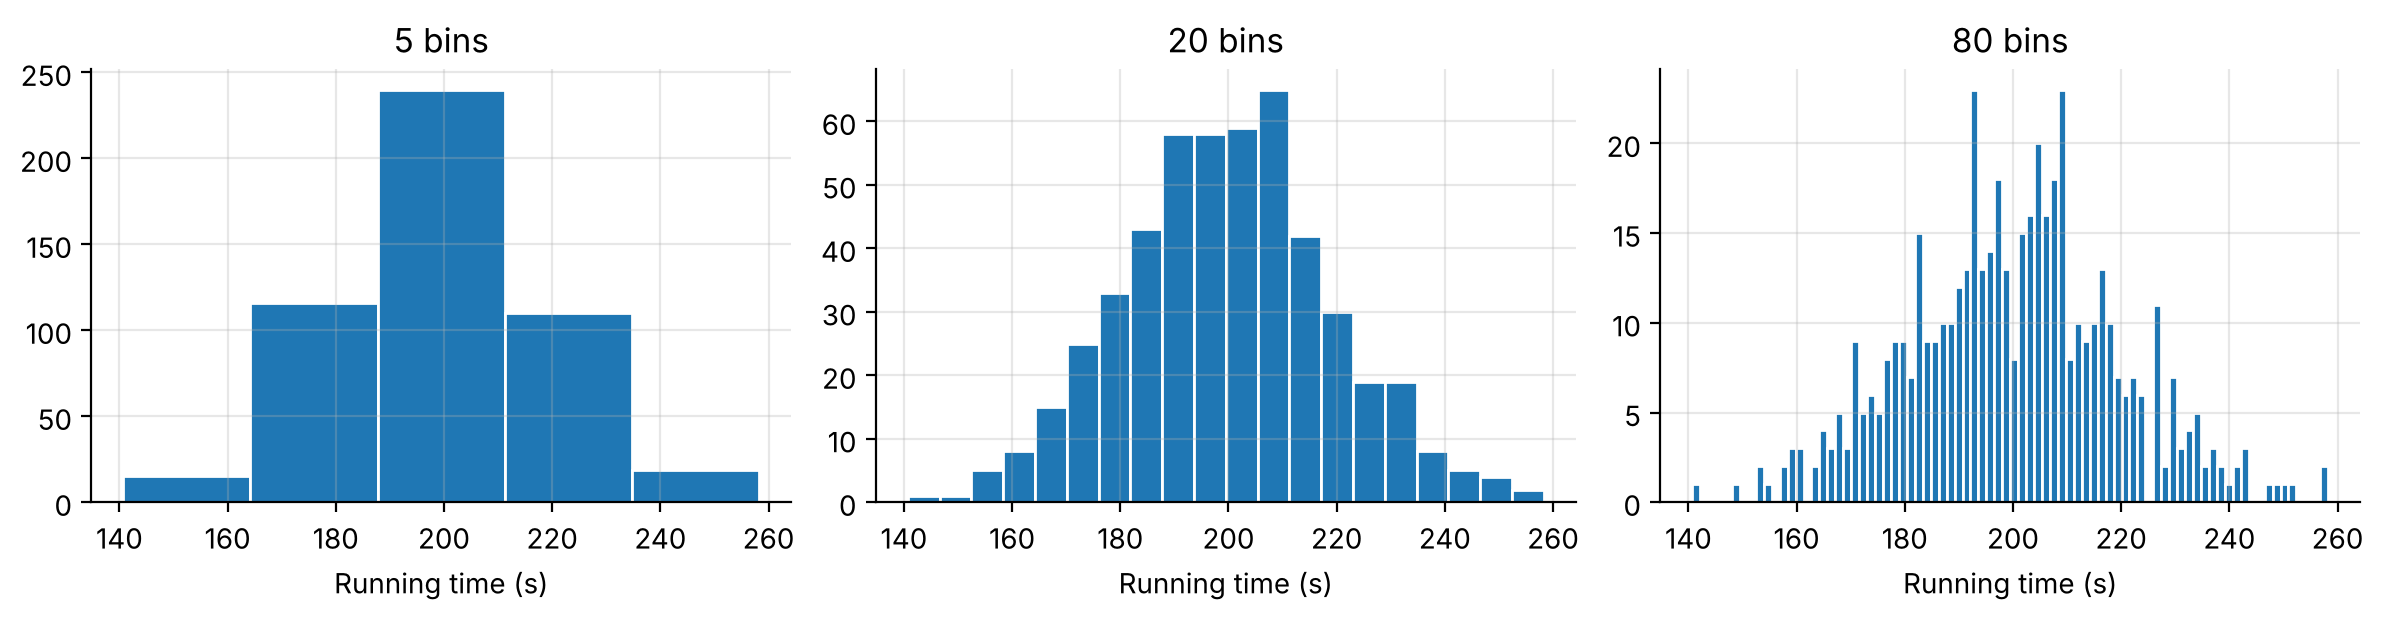

In [6]:
running_time = rng.normal(loc=200, scale=20, size=500)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=False)
for ax, bins in zip(axes, [5, 20, 80]):
    ax.hist(running_time, bins=bins, edgecolor="white")
    ax.set_title(f"{bins} bins")
    ax.set_xlabel("Running time (s)")
plt.tight_layout()
plt.show()

### Scatter plots show relationships

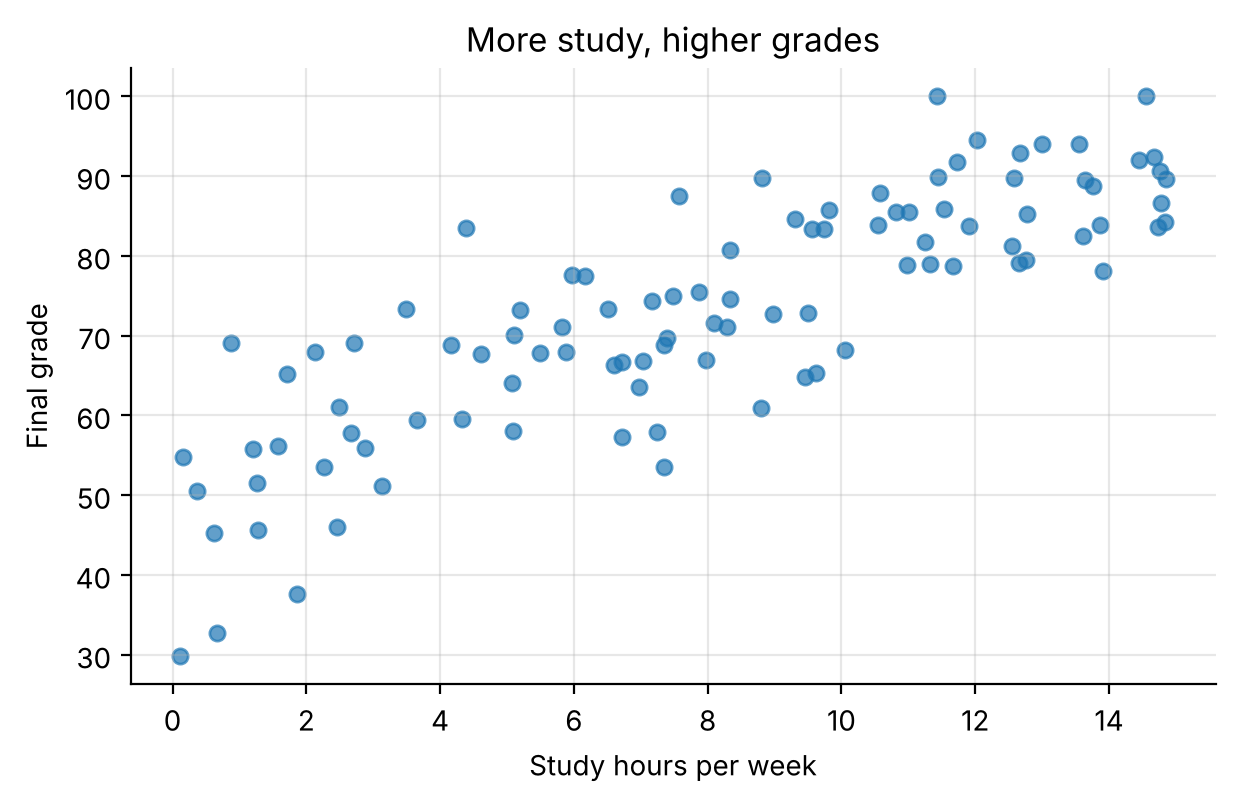

In [7]:
hours = rng.uniform(0, 15, 100)
grade = np.clip(50 + 3 * hours + rng.normal(0, 8, 100), 0, 100)

fig, ax = plt.subplots()
ax.scatter(hours, grade, alpha=0.7, s=30)
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Final grade")
ax.set_title("More study, higher grades")
plt.show()

### Box plots summarise and compare distributions

The box spans the 25th to 75th percentile (the interquartile range, IQR), the line is the median, the whiskers reach the furthest points within 1.5 × IQR, and dots beyond are potential outliers.

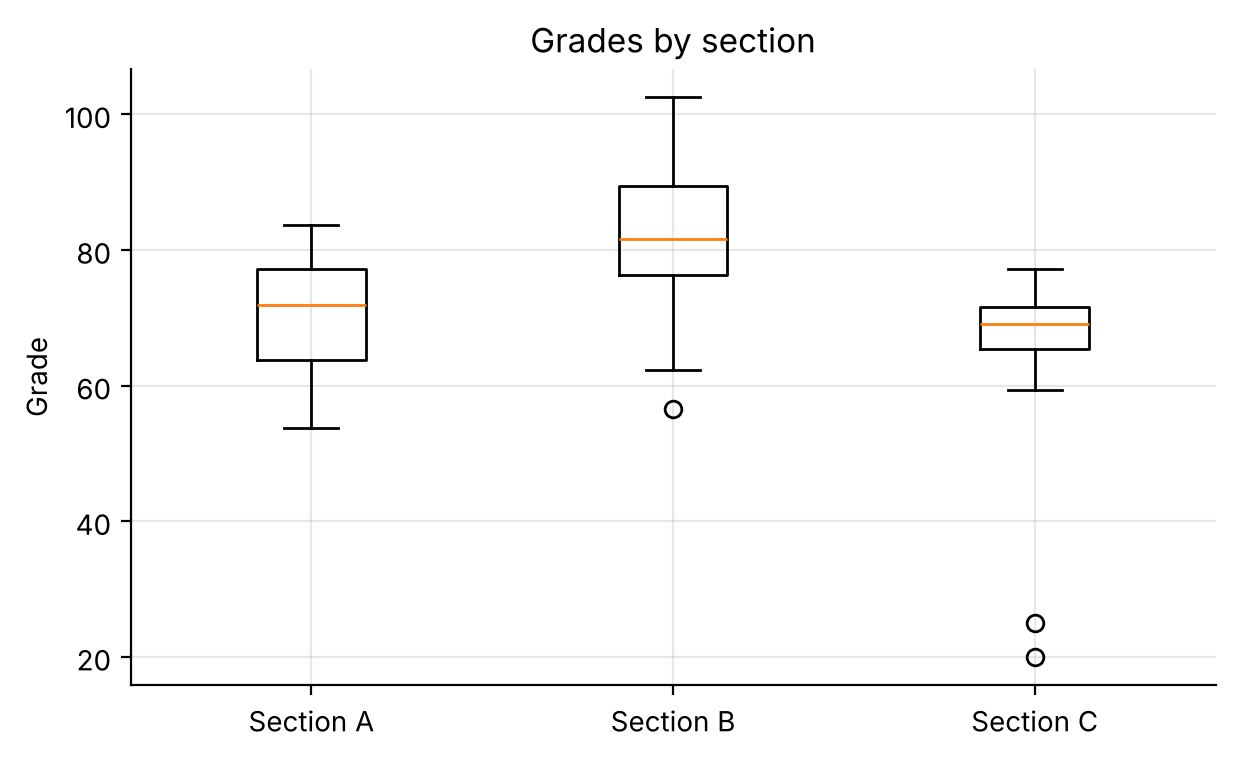

In [8]:
groups = {"Section A": rng.normal(72, 8, 40), "Section B": rng.normal(78, 12, 40),
          "Section C": np.append(rng.normal(70, 5, 38), [20, 25])}
fig, ax = plt.subplots()
ax.boxplot(list(groups.values()), tick_labels=list(groups.keys()))
ax.set_ylabel("Grade")
ax.set_title("Grades by section")
plt.show()

## 3. Charts that mislead

Four countries' GDP. Which statements are true?

- A. Country D has a similar growth rate to the others.
- B. From 1950 to 1970 the GDP of all four countries did not change much.
- C. From 1980 to 2010 country C grew much faster than country A.

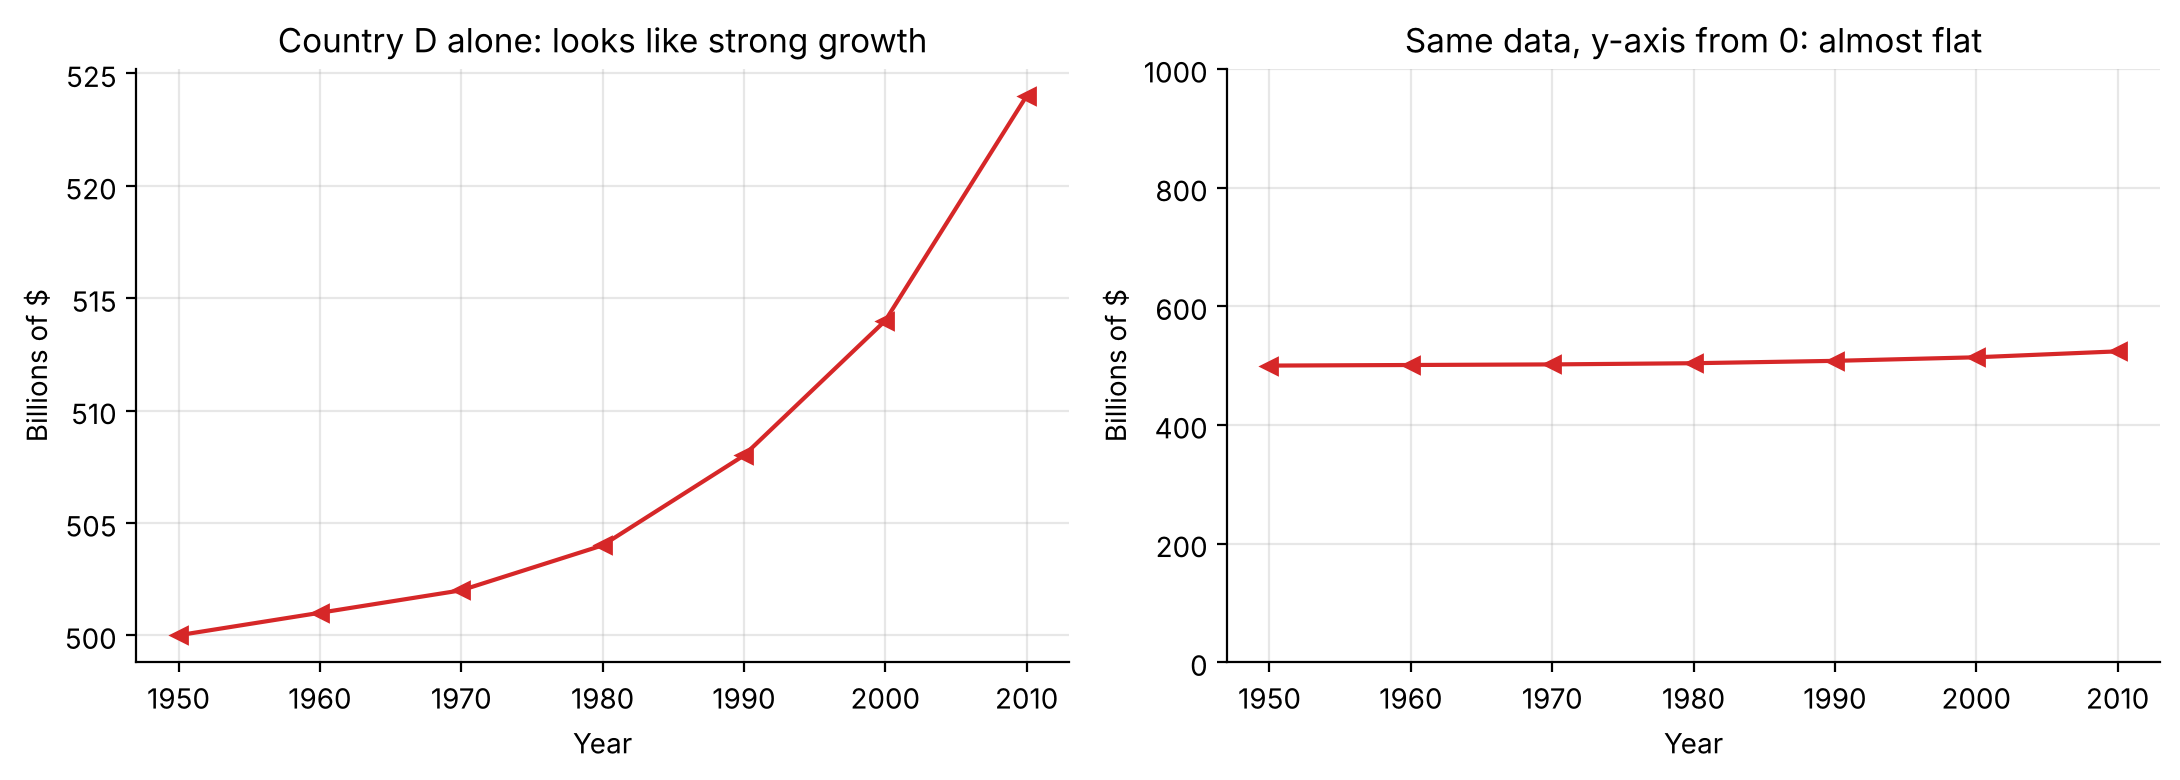

In [9]:
gdp_a = [300.2, 543.3, 1075.9, 2862.5, 5979.6, 10289.7, 14958.3]
gdp_b = [226.0, 362.0, 928.0, 1992.0, 4931.0, 7488.0, 12147.0]
gdp_c = [1206.0, 1057.0, 1081.0, 2940.0, 8813.0, 13502.0, 19218.0]
gdp_d = [500, 501, 502, 504, 508, 514, 524]
series = {"Country A": gdp_a, "Country B": gdp_b, "Country C": gdp_c, "Country D": gdp_d}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(years, gdp_d, marker="<", color="tab:red")
axes[0].set_title("Country D alone: looks like strong growth")
axes[1].plot(years, gdp_d, marker="<", color="tab:red")
axes[1].set_ylim(0, 1000)
axes[1].set_title("Same data, y-axis from 0: almost flat")
for ax in axes:
    ax.set_xlabel("Year")
    ax.set_ylabel("Billions of $")
plt.tight_layout()
plt.show()

On a linear scale, early changes look flat because later values are much larger. A **log scale** shows **growth rates**: equal slopes mean equal percentage growth.

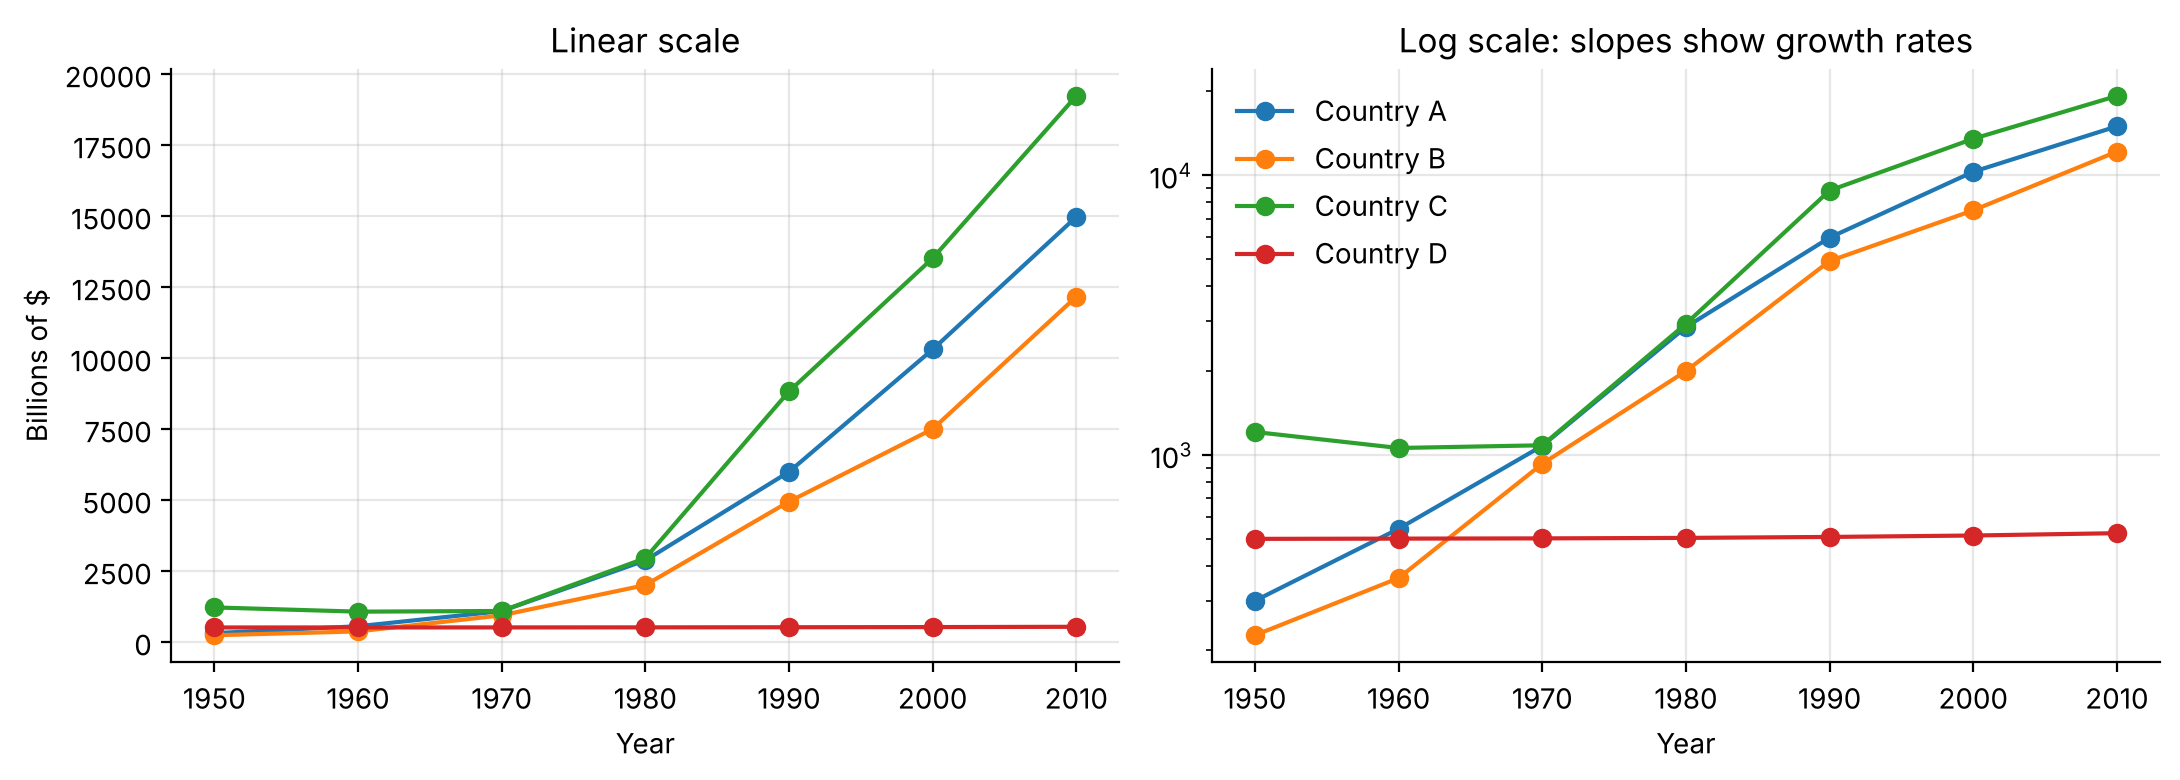

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, values in series.items():
    axes[0].plot(years, values, marker="o", label=name)
    axes[1].plot(years, values, marker="o", label=name)
axes[0].set_title("Linear scale")
axes[1].set_yscale("log")
axes[1].set_title("Log scale: slopes show growth rates")
for ax in axes:
    ax.set_xlabel("Year")
axes[0].set_ylabel("Billions of $")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

**Rules of thumb**

- Bars start at zero. Lines may zoom, but say so.
- Compare growth on a log scale or as percentage change.
- Never use two different y-axes on one chart; use two charts side by side.
- Label axes with units; give the chart a title that states the finding.

## 4. Styling and saving

Format strings are a shortcut: `"bo-"` = blue, circle markers, solid line. Named arguments are clearer.

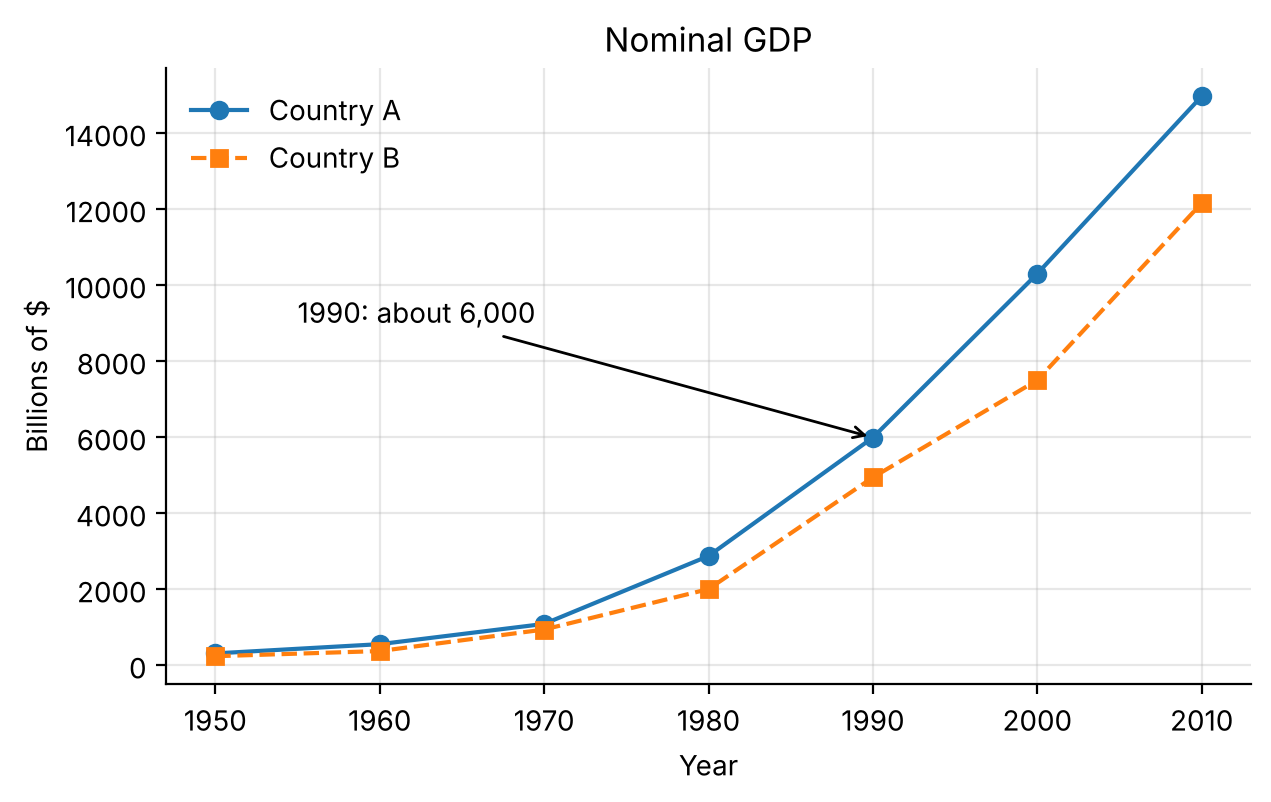

In [11]:
fig, ax = plt.subplots()
ax.plot(years, gdp_a, color="tab:blue", marker="o", linestyle="-", label="Country A")
ax.plot(years, gdp_b, color="tab:orange", marker="s", linestyle="--", label="Country B")
ax.annotate("1990: about 6,000", xy=(1990, 5979.6), xytext=(1955, 9000),
            arrowprops=dict(arrowstyle="->"))
ax.set(title="Nominal GDP", xlabel="Year", ylabel="Billions of $", xticks=years)
ax.legend(frameon=False)
fig.savefig("gdp.png", dpi=150, bbox_inches="tight")   # also .pdf or .svg
plt.show()

## 5. Several plots in one figure

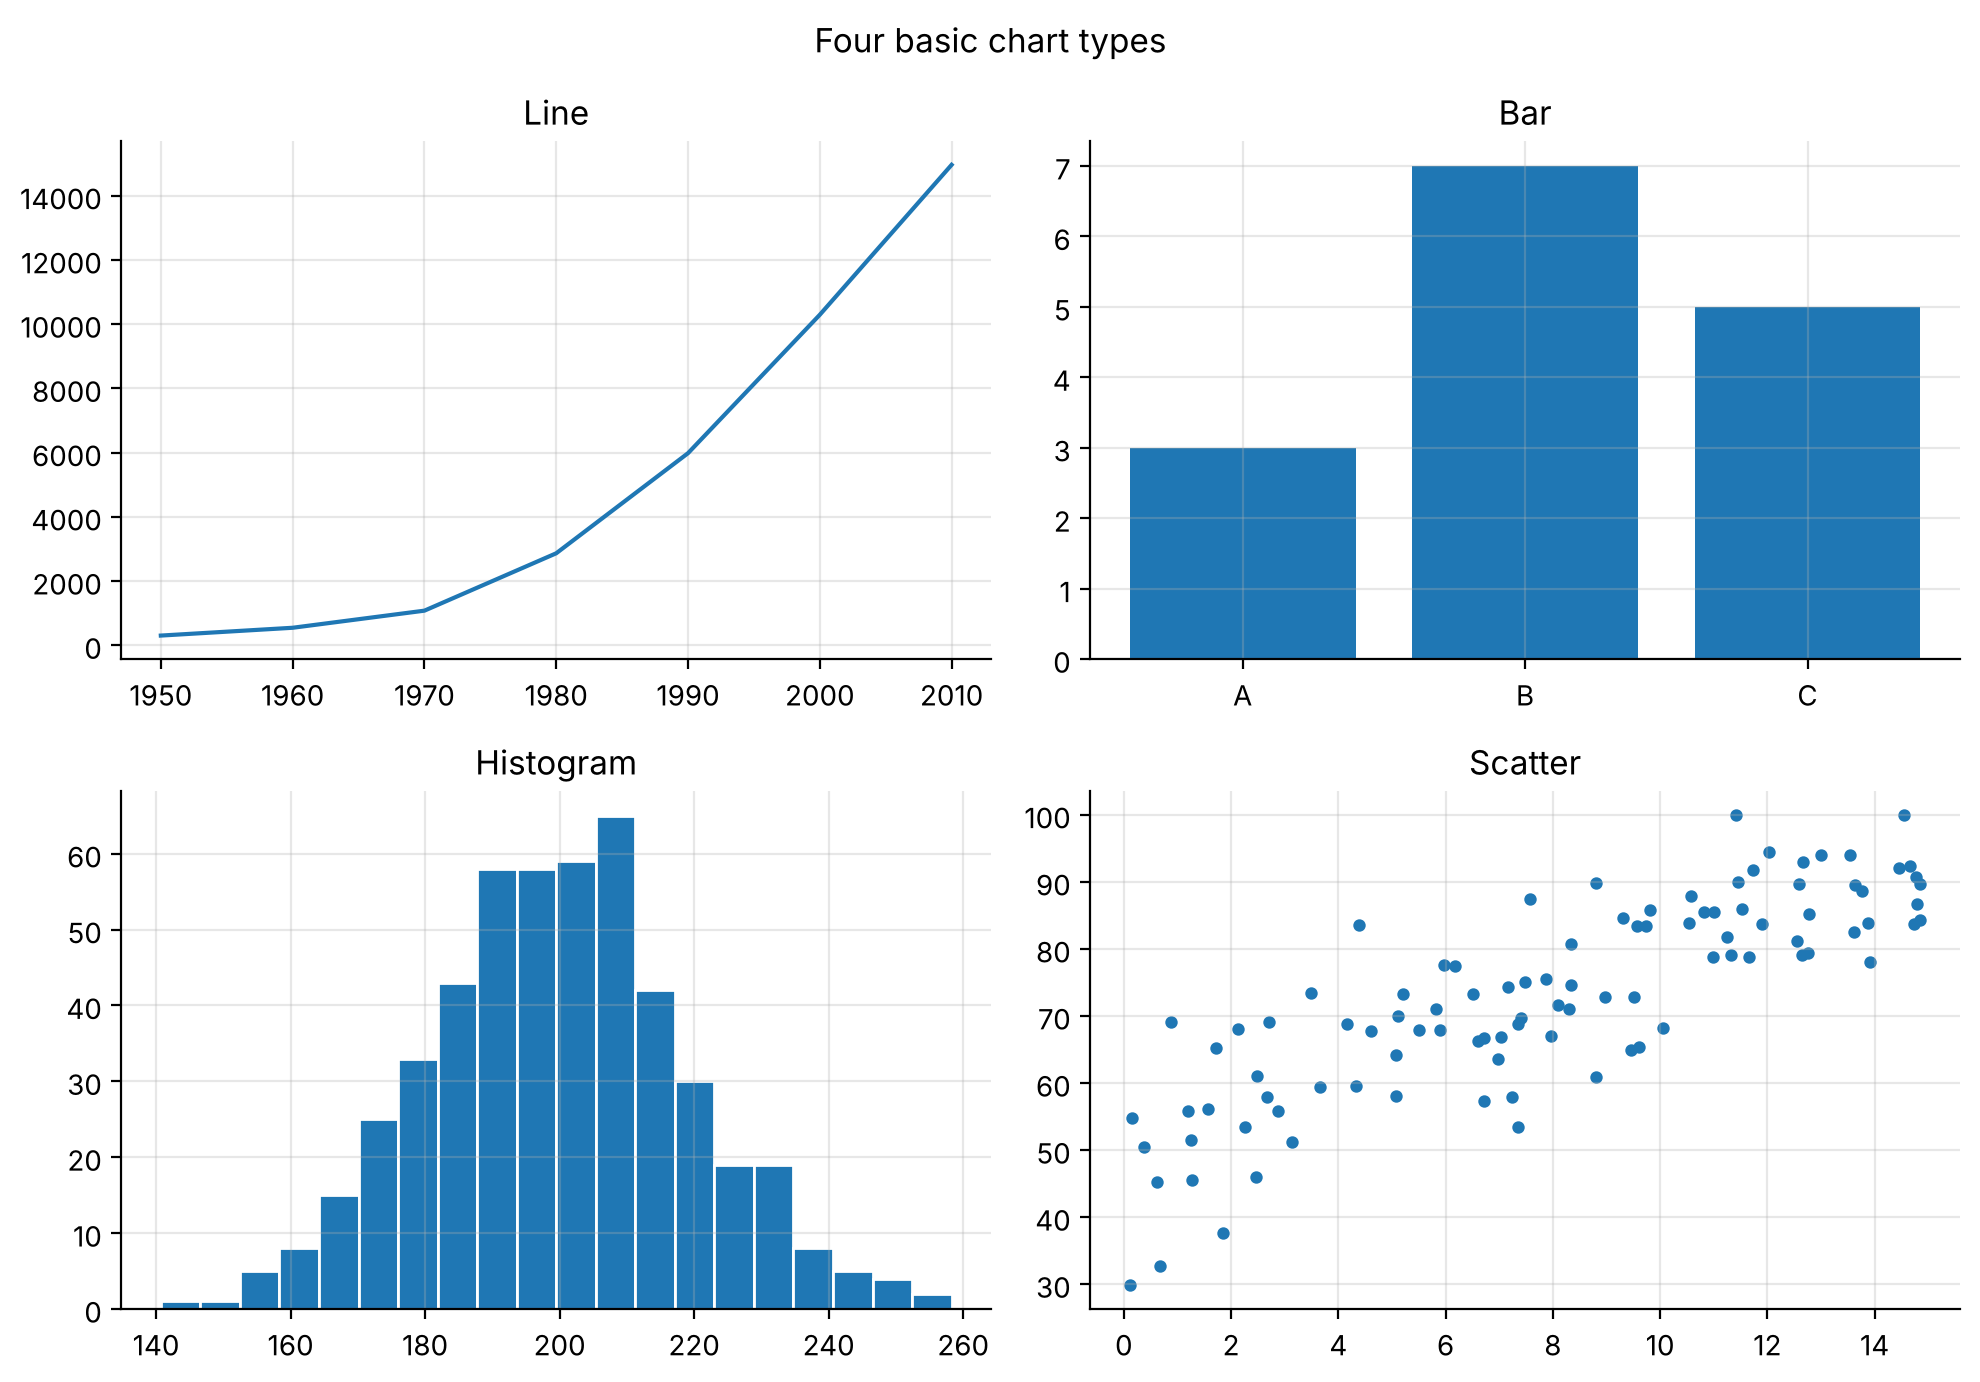

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].plot(years, gdp_a)
axes[0, 0].set_title("Line")
axes[0, 1].bar(["A", "B", "C"], [3, 7, 5])
axes[0, 1].set_title("Bar")
axes[1, 0].hist(running_time, bins=20, edgecolor="white")
axes[1, 0].set_title("Histogram")
axes[1, 1].scatter(hours, grade, s=12)
axes[1, 1].set_title("Scatter")
fig.suptitle("Four basic chart types")
plt.tight_layout()
plt.show()

`imshow` draws a matrix as an image, useful for correlation matrices and heatmaps:

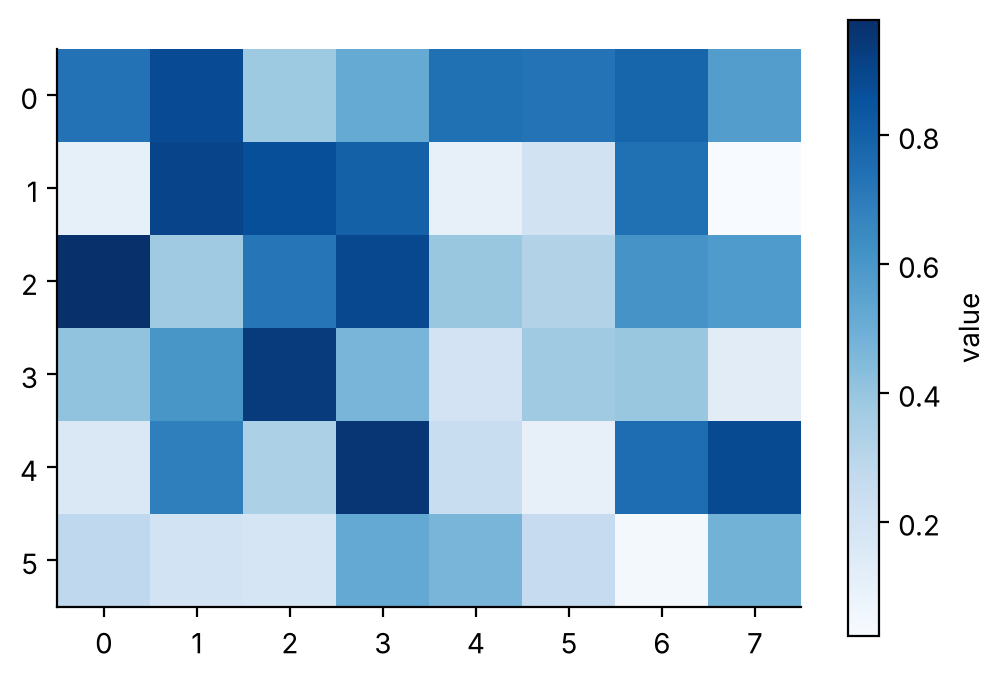

In [13]:
matrix = rng.random((6, 8))
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(matrix, cmap="Blues")
fig.colorbar(im, ax=ax, label="value")
ax.grid(False)
plt.show()

## 6. Plotting directly from pandas

Every DataFrame and Series has a `.plot` method built on Matplotlib.

In [14]:
students = pd.read_csv(data_file("students.csv")).drop_duplicates()
students["program"] = students["program"].str.upper()
students = students[(students["final"] >= 0) & (students["study_hours_per_week"] <= 80)]
students.head()

,student_id,name,gender,program,study_hours_per_week,midterm1,midterm2,final
0,S2025000,Sara,F,MDS,6.5,71.0,54.0,64.0
1,S2025001,Maha,F,MIS,4.5,73.0,85.0,71.0
2,S2025002,Sara,F,MIS,1.7,57.0,51.0,42.0
3,S2025003,Maha,F,MIS,3.6,71.0,67.0,48.0
5,S2025005,Aisha,F,MDS,1.2,75.0,70.0,67.0


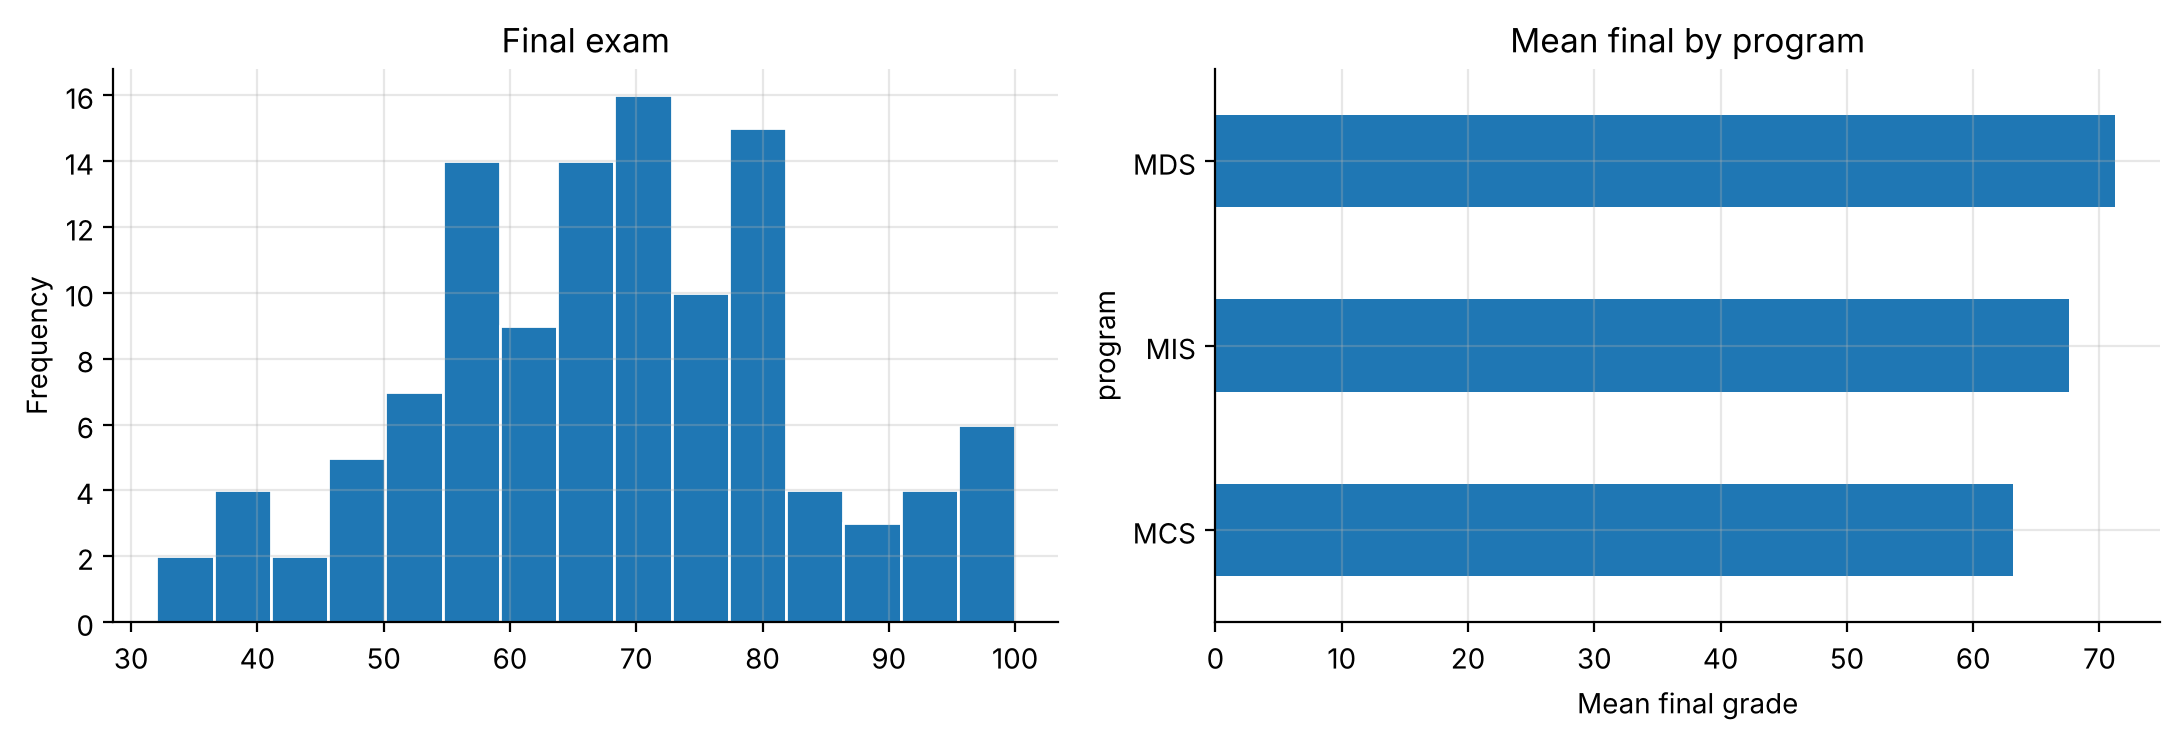

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
students["final"].plot.hist(bins=15, edgecolor="white", ax=axes[0], title="Final exam")
students.groupby("program")["final"].mean().sort_values().plot.barh(ax=axes[1], title="Mean final by program")
axes[1].set_xlabel("Mean final grade")
plt.tight_layout()
plt.show()

## 7. Statistical plots with seaborn

**seaborn** works directly with DataFrames in long format: you name the columns for `x`, `y` and `hue`.

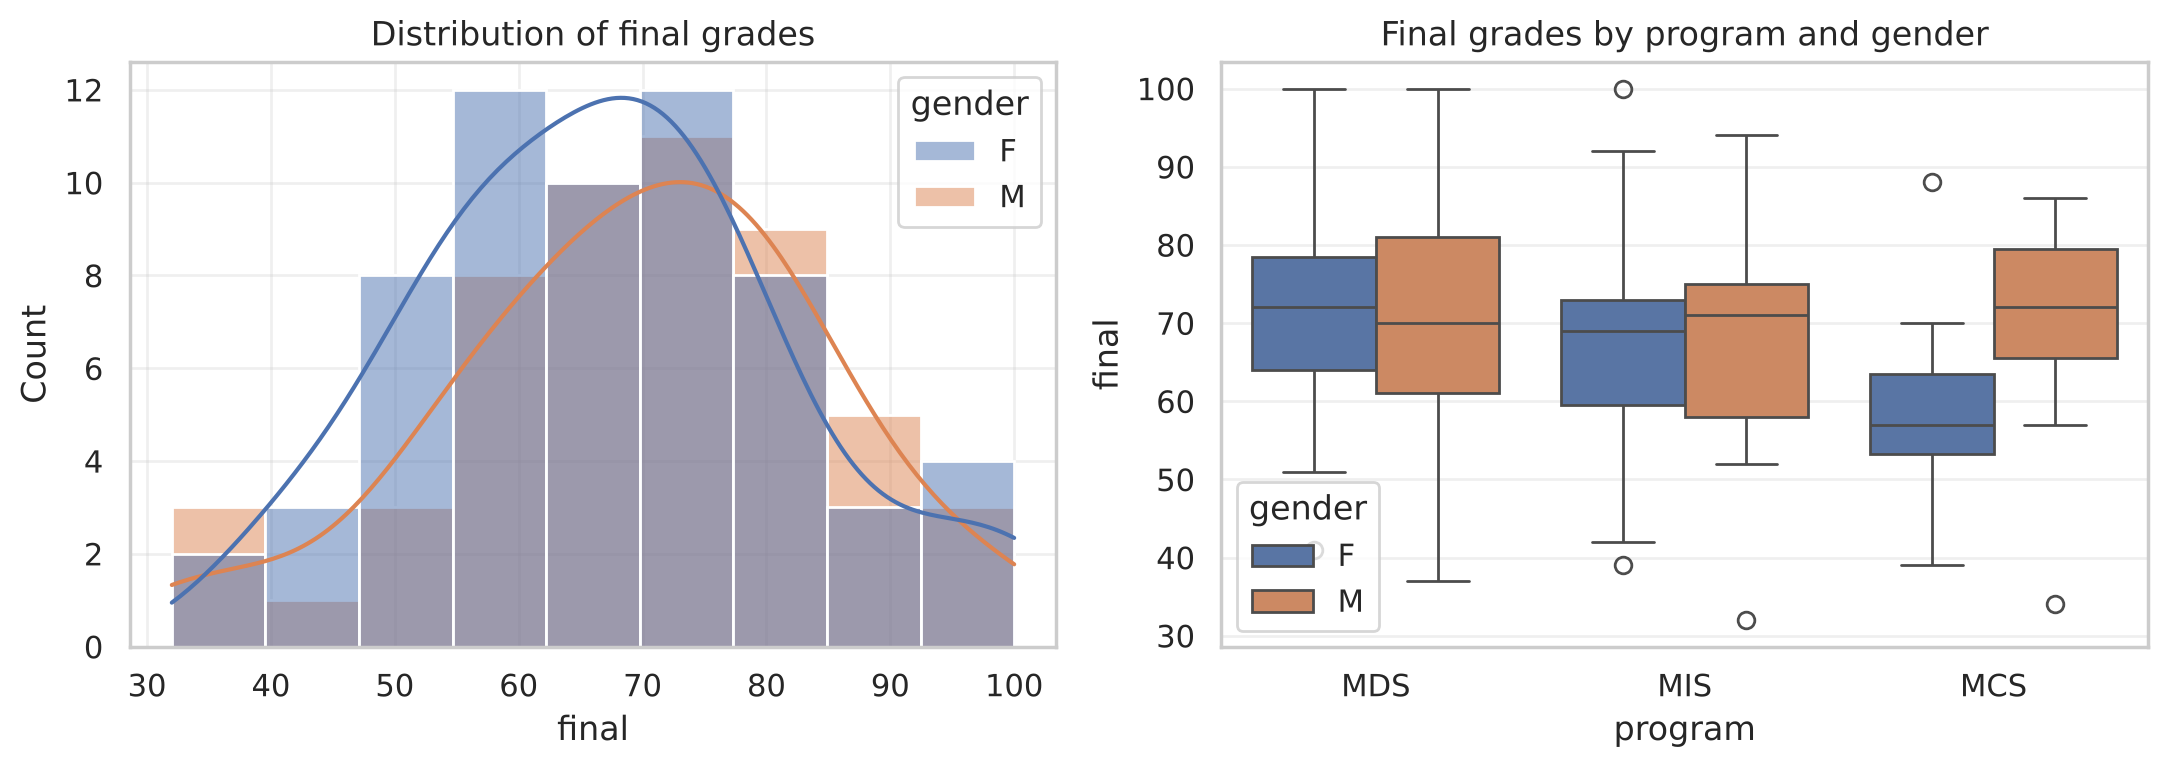

In [16]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=students, x="final", hue="gender", kde=True, ax=axes[0])
sns.boxplot(data=students, x="program", y="final", hue="gender", ax=axes[1])
axes[0].set_title("Distribution of final grades")
axes[1].set_title("Final grades by program and gender")
plt.tight_layout()
plt.show()

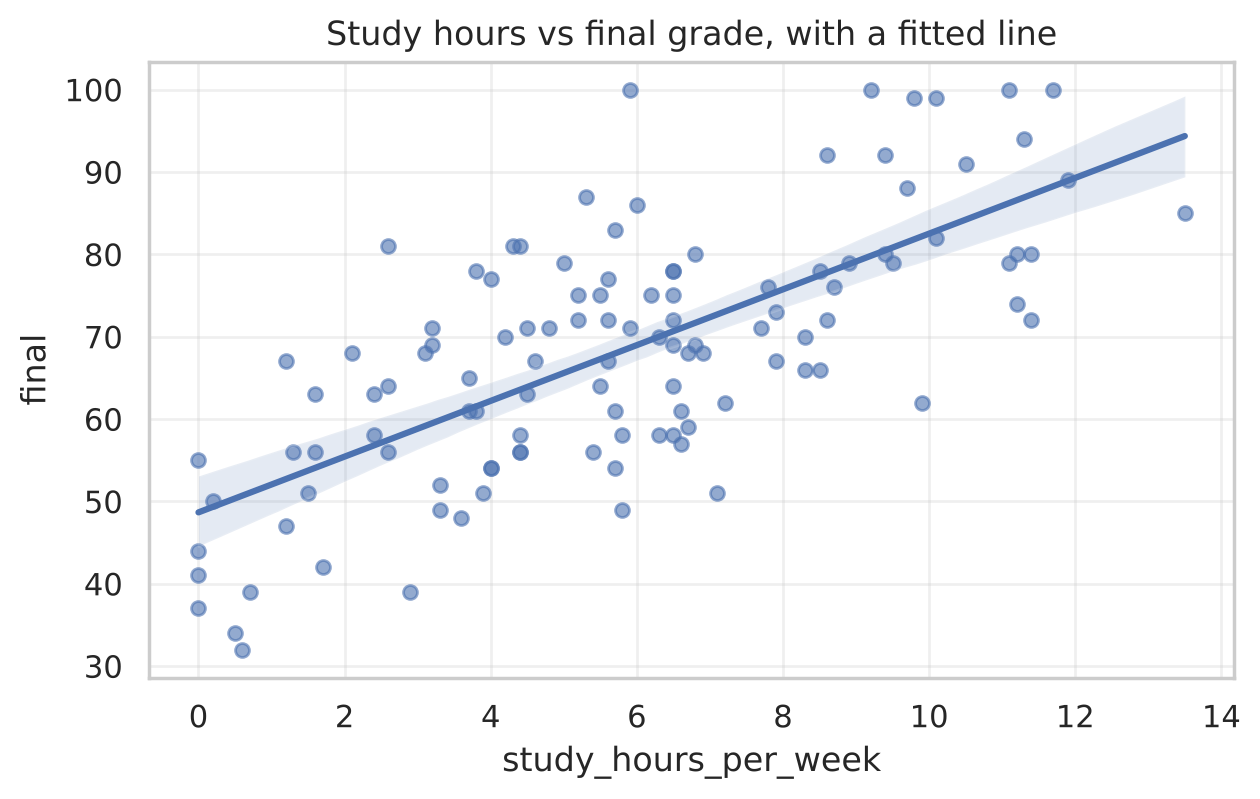

In [17]:
sns.regplot(data=students, x="study_hours_per_week", y="final",
            scatter_kws={"alpha": 0.6, "s": 25})
plt.title("Study hours vs final grade, with a fitted line")
plt.show()

## 8. Descriptive statistics and correlation

| Measure | pandas | Sensitive to outliers? |
|---|---|---|
| mean | `.mean()` | yes |
| median | `.median()` | no |
| standard deviation | `.std()` | yes |
| interquartile range | `.quantile(0.75) - .quantile(0.25)` | no |
| range | `.max() - .min()` | very |

In [18]:
exams = students[["midterm1", "midterm2", "final", "study_hours_per_week"]]
exams.agg(["mean", "median", "std", "min", "max"]).round(1)

,midterm1,midterm2,final,study_hours_per_week
mean,70.4,68.6,68.2,5.8
median,70.0,68.0,69.0,5.7
std,11.1,12.9,15.1,3.2
min,38.0,37.0,32.0,0.0
max,96.0,100.0,100.0,13.5


**Correlation** (Pearson's *r*, from −1 to 1) measures how well a **straight line** describes the relationship. It says nothing about causation, and it can miss strong non-linear relationships.

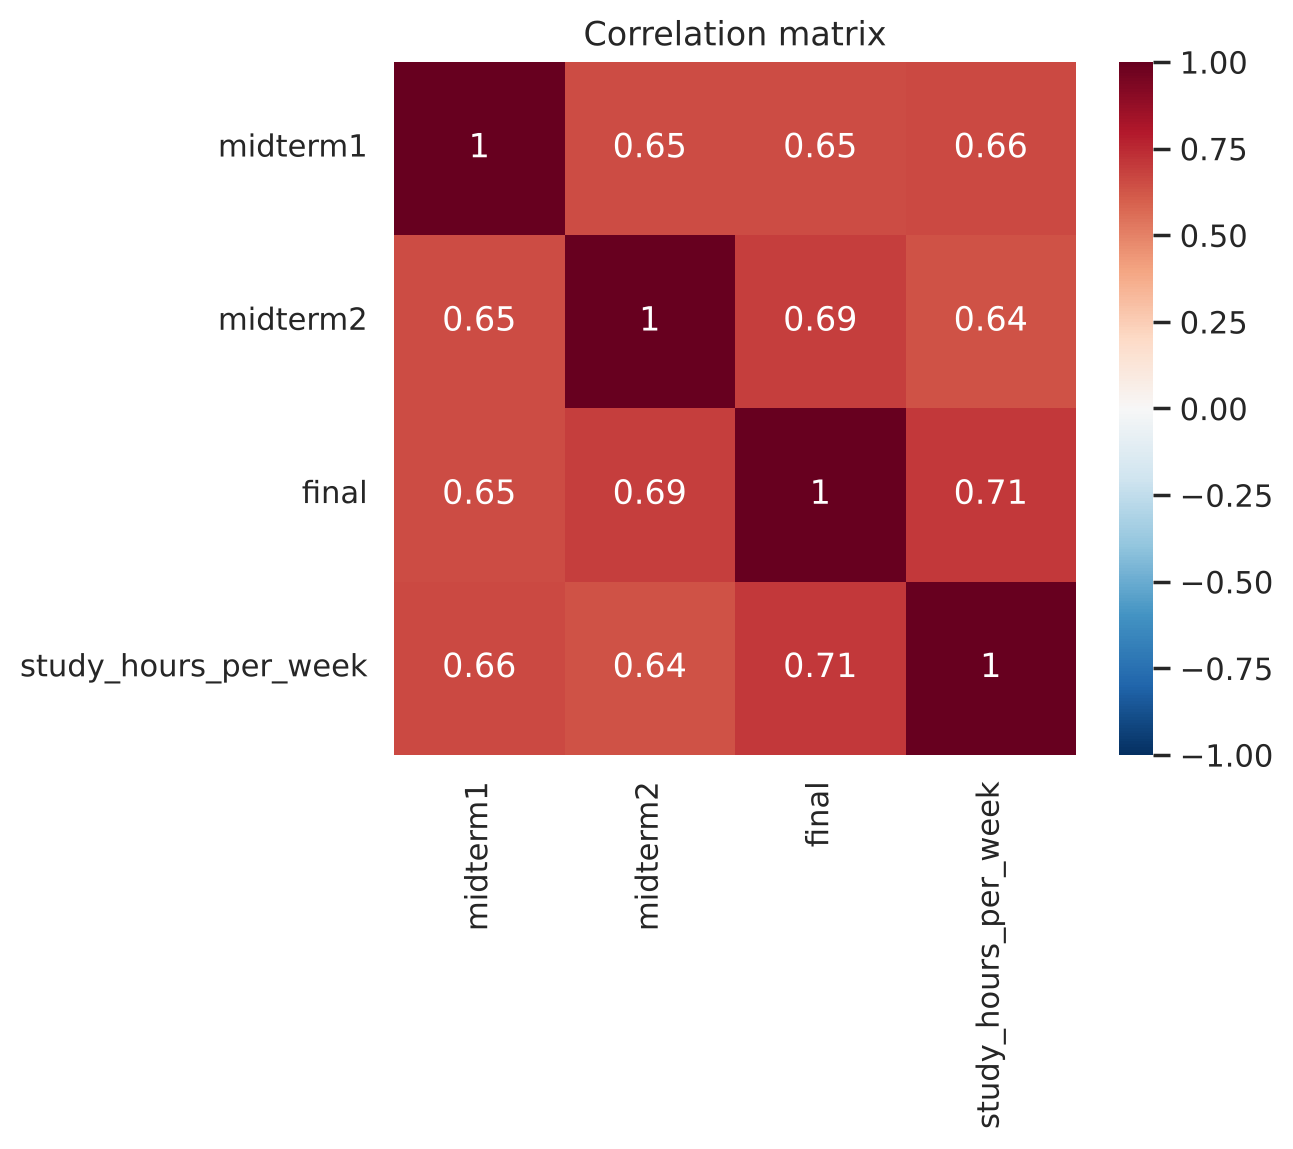

In [19]:
corr = exams.corr().round(2)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

Anscombe's quartet: four datasets with the same means, variances and correlation, which look completely different. **Always plot your data.**

     mean_y     r
set              
I       7.5  0.82
II      7.5  0.82
III     7.5  0.82
IV      7.5  0.82


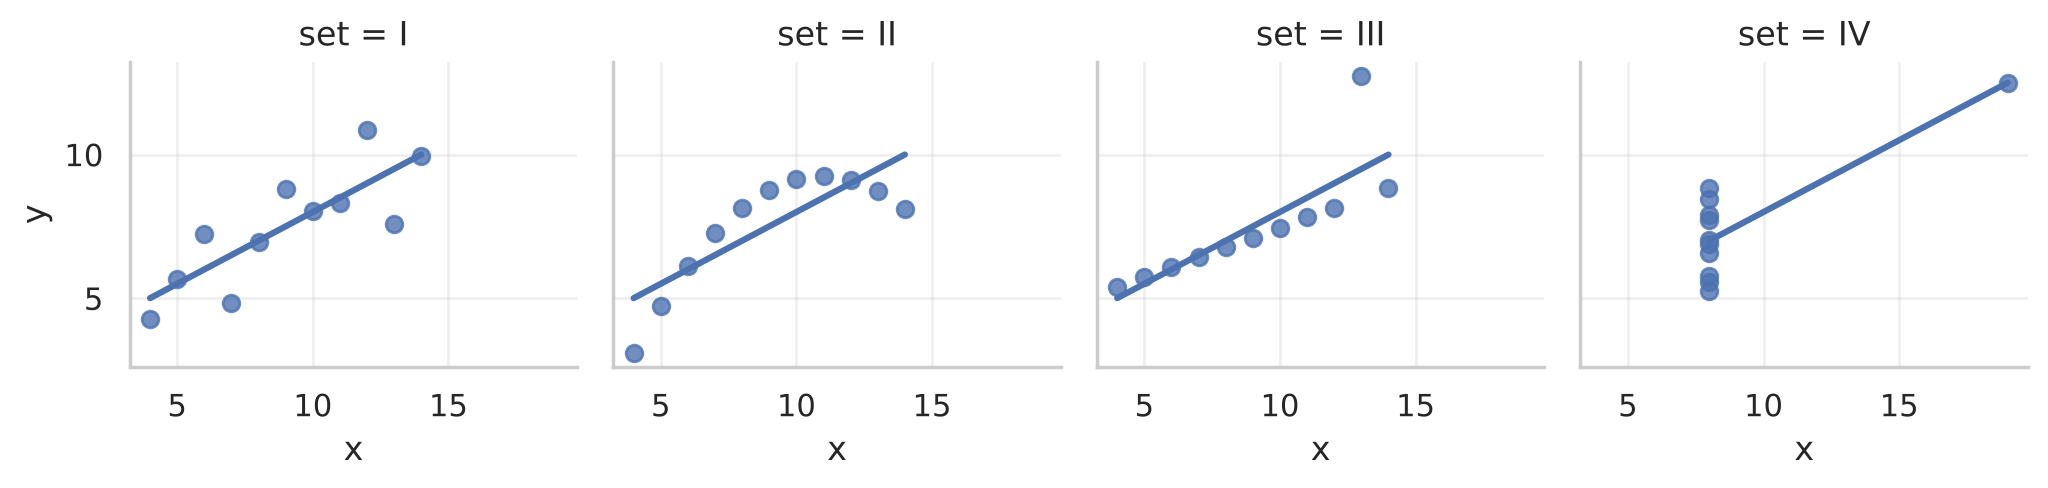

In [20]:
anscombe = pd.DataFrame({
    "x":  [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5] * 3 + [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
    "y":  [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68,
           9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74,
           7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73,
           6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89],
    "set": np.repeat(["I", "II", "III", "IV"], 11),
})
print(anscombe.groupby("set").apply(lambda d: pd.Series({"mean_y": d["y"].mean(), "r": d["x"].corr(d["y"])}),
                                    include_groups=False).round(2))
sns.lmplot(data=anscombe, x="x", y="y", col="set", col_wrap=4, height=2.6, ci=None)
plt.show()

## 9. Comparing groups: the t-test

Do female and male students score differently on the final? The difference in sample means could be due to chance. A **two-sample t-test** gives a *p-value*: the probability of seeing a difference at least this large if the true means were equal.

In [21]:
from scipy import stats

female = students.loc[students["gender"] == "F", "final"]
male = students.loc[students["gender"] == "M", "final"]
print(f"mean F = {female.mean():.1f}, mean M = {male.mean():.1f}")

result = stats.ttest_ind(female, male, equal_var=False)   # Welch's t-test
print(f"t = {result.statistic:.2f}, p = {result.pvalue:.3f}")

mean F = 67.1, mean M = 69.5
t = -0.84, p = 0.404


With the usual threshold of 0.05, a p-value above 0.05 means we **cannot conclude** there is a difference; it does not prove the means are equal.

Other common tests in `scipy.stats`:

| Question | Test |
|---|---|
| Same student, two exams (paired data) | `stats.ttest_rel` |
| More than two groups | `stats.f_oneway` (ANOVA) |
| Two categorical variables | `stats.chi2_contingency` |
| Correlation significantly different from 0 | `stats.pearsonr` |

In [22]:
paired = stats.ttest_rel(students["midterm1"], students["final"])
r = stats.pearsonr(students["study_hours_per_week"], students["final"])
print(f"midterm1 vs final (paired): p = {paired.pvalue:.3f}")
print(f"hours vs final: r = {r.statistic:.2f}, p = {r.pvalue:.2g}")

midterm1 vs final (paired): p = 0.042
hours vs final: r = 0.71, p = 1.3e-18


**Error bars** show uncertainty. Here: mean final per program with a 95% confidence interval.

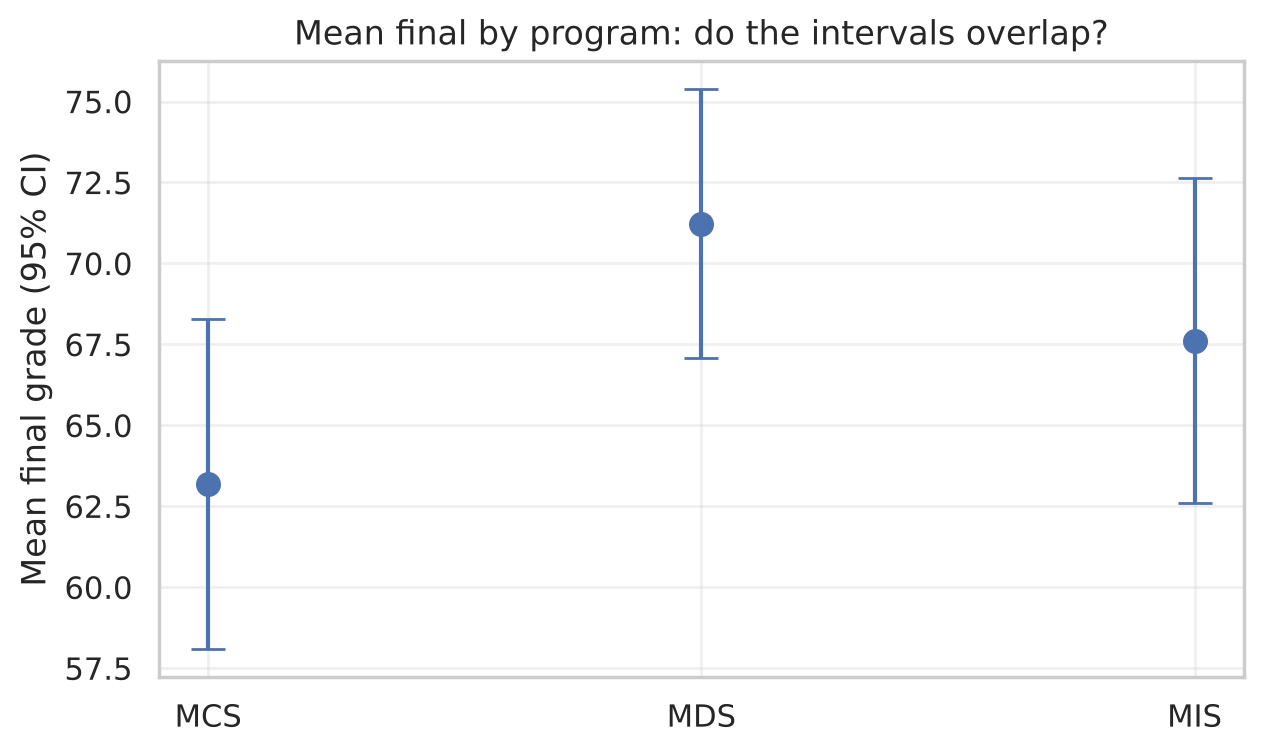

In [23]:
summary = students.groupby("program")["final"].agg(["mean", "sem"])
fig, ax = plt.subplots()
ax.errorbar(summary.index, summary["mean"], yerr=1.96 * summary["sem"], fmt="o", capsize=6, markersize=8)
ax.set_ylabel("Mean final grade (95% CI)")
ax.set_title("Mean final by program: do the intervals overlap?")
plt.show()

## 10. A taste of interactive charts with Plotly

Plotly charts let the reader hover, zoom and filter. They work in Colab and in notebooks on GitHub (static preview).

In [24]:
import plotly.express as px

fig = px.scatter(students, x="study_hours_per_week", y="final", color="program",
                 hover_data=["student_id", "name"], title="Hover over a point")
fig.show()

## Summary

- Pick the chart from the question: trend → line, comparison → bar, distribution → histogram/box, relationship → scatter.
- Use `fig, ax = plt.subplots()` and the `ax.` methods.
- Watch for misleading axes; prefer log scales for growth; never use dual y-axes.
- Describe data with mean/median/std/IQR, plot it before trusting a statistic, and test differences before claiming them.